# Chapter 1: Two distances

Checks the worked example of [chapter 1](../../book/01-two-distances.md), its three
"check yourself" answers, and the claim that the nearest distance is never larger than the
vertical error. These are measurements. Chapter 3 proves the claim.

Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
from common import *

use_style()

## The example: the line `y = 3x` and the data point `(0, 1)`

The vertical error is the distance straight down to the line. The nearest distance is the
shortest distance to any point of the line. The chapter says they are `1` and `1 / √10`.

In [2]:
line = lambda inputs: 3.0 * inputs
slope_limit = 3.0
data_point = (0.0, 1.0)

vertical_error = get_vertical_error(line(torch.tensor(data_point[0])), data_point[1])
nearest_distance = get_nearest_distance(line, *data_point, slope_limit, resolution=1e-5)
exact_nearest_distance = 1 / math.sqrt(10)

report("vertical error of y = 3x at (0, 1) is 1", abs(vertical_error - 1.0) < 1e-12)
report("nearest distance is 1 / sqrt(10) = 0.3162", abs(nearest_distance - exact_nearest_distance) < 1e-4,
       f"measured {nearest_distance:.5f}")

[PASS] vertical error of y = 3x at (0, 1) is 1
[PASS] nearest distance is 1 / sqrt(10) = 0.3162  (measured 0.31623)


True

## Check yourself, question 1

The model is the flat line `y = 0` and the data point is `(2, 5)`. The chapter answers: both
distances are 5.

In [3]:
flat = lambda inputs: 0.0 * inputs
flat_vertical_error = get_vertical_error(flat(torch.tensor(2.0)), 5.0)
flat_nearest_distance = get_nearest_distance(flat, 2.0, 5.0, slope_limit=0.0)

report("flat line: both distances are 5", flat_vertical_error == 5.0 and abs(flat_nearest_distance - 5.0) < 1e-9)

[PASS] flat line: both distances are 5


True

## Check yourself, question 2: the nearest distance is never larger than the vertical error

Random sine models of 1, 2, 5 and 12 terms, and 300 random data points for each. The nearest distance is
measured with `include_foot=False`: the point straight above or below the data point is not one of the
samples, so nothing forces the answer to stay under the vertical error. The allowed excess is the
polyline error, `3e-4`.

In [4]:
generator = torch.Generator().manual_seed(1)
largest_excess = -1.0
trial_count = 0

for num_terms in (1, 2, 5, 12):
    model = SineModel(num_terms, generator=generator)
    model_slope_limit = model.get_slope_limit()
    points = torch.rand(2, 300, generator=generator) * 2 - 1
    for point_x, point_y in points.T:
        vertical_error = get_vertical_error(model(point_x.reshape(1)), point_y)
        nearest_distance = get_nearest_distance(model, point_x, point_y, model_slope_limit, resolution=2e-3,
                                                include_foot=False)
        largest_excess = max(largest_excess, nearest_distance - vertical_error)
        trial_count += 1

report("nearest distance never exceeds the vertical error", largest_excess <= 3e-4,
       f"{trial_count} trials, largest nearest - vertical = {largest_excess:.2e}")

[PASS] nearest distance never exceeds the vertical error  (1200 trials, largest nearest - vertical = -2.41e-07)


True

## Figure for the chapter

Written to `book/figures/01-two-distances-line.png`.

wrote book/figures/01-two-distances-line.png


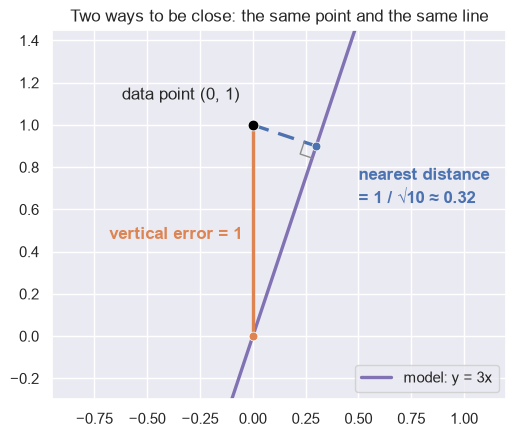

In [5]:
foot_of_perpendicular = (0.3, 0.9)      # the nearest point of y = 3x to (0, 1)
xs = np.linspace(-0.9, 1.2, 200)

figure, axis = plt.subplots(figsize=(7.4, 4.8))
sns.lineplot(x=xs, y=3 * xs, color=MODEL, linewidth=2.4, label="model: y = 3x", ax=axis)
axis.plot([0, 0], [1, 0], color=VERTICAL, linewidth=2.4)
axis.plot([0, foot_of_perpendicular[0]], [1, foot_of_perpendicular[1]], color=NEAREST, linewidth=2.4,
          linestyle=(0, (5, 3)))
sns.scatterplot(x=[0], y=[1], color=DATA, s=60, zorder=5, ax=axis, legend=False)
sns.scatterplot(x=[foot_of_perpendicular[0]], y=[foot_of_perpendicular[1]], color=NEAREST, s=40, zorder=5, ax=axis, legend=False)
sns.scatterplot(x=[0], y=[0], color=VERTICAL, s=40, zorder=5, ax=axis, legend=False)

corner = np.array(foot_of_perpendicular)       # the right-angle mark
toward_point, along_line = np.array([-0.3, 0.1]), np.array([-0.1, -0.3])
toward_point, along_line = toward_point / np.linalg.norm(toward_point) * 0.06, along_line / np.linalg.norm(along_line) * 0.06
axis.plot(*zip(corner + toward_point, corner + toward_point + along_line, corner + along_line), color=MUTED, linewidth=1)

axis.annotate("data point (0, 1)", (0, 1), xytext=(-0.62, 1.12))
axis.text(-0.05, 0.46, "vertical error = 1", color=VERTICAL, ha="right", fontweight="bold")
axis.text(0.50, 0.74, "nearest distance", color=NEAREST, fontweight="bold")
axis.text(0.50, 0.63, "= 1 / √10 ≈ 0.32", color=NEAREST, fontweight="bold")
axis.set(xlim=(-0.95, 1.2), ylim=(-0.3, 1.45), aspect="equal",
         title="Two ways to be close: the same point and the same line")
axis.legend(loc="lower right")
save_figure(figure, "01-two-distances-line")